In [1]:
######### DARING_CAMONET_dnd_ for combined data
## The scripit caters for the severe class imbalance
## This script does bootstrap oversampling combined with class balancing
## Oversampling occurs only on training folds
## Script forces a 30:70 representation of mortality. This ensures that at each iteration, both classes are represented
## It also applies Balanced Random Forest and EasY Ensemble that control class imbalance internally. This kind of controls the 
## the attempts made to deal with the imbalance
## ## The calibration set is not used during model training or hyperparameter tuning
## The test set is not used during model training or hyperparameter tuning
## Script saves 10 models (you can change) for each ML method. This allows to look on the distribution of the metrics, and make assessment of their
## performance and variability across different training runs. But only one best model is selected per ML method at the end of the day.
## Script save all results in csvs, validation, calibration and testing

In [2]:
import os
os.environ["SCIPY_ARRAY_API"] = "1"

import numpy as np
import pandas as pd
import pickle

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    brier_score_loss,
    roc_auc_score,
    average_precision_score
)

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier

import imblearn

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier
from sklearn.utils import resample




In [3]:
data = pd.read_csv("/home/kyomukama/ACE/camonet/Mortality model/Data/DaringCamonet_combined_processedData.csv")

In [4]:
data.head()

,site,age,sex,ward,anyComorbidity,anyResistance,antib_prior_admi,treatOutcome
0,0,3.610918,1,0,0,0,1,0
1,0,4.060443,1,3,0,1,0,0
2,0,2.197225,1,0,0,1,0,0
3,0,0.693147,0,4,0,0,1,0
4,0,3.091042,1,0,0,1,0,0


In [5]:
data.tail()

,site,age,sex,ward,anyComorbidity,anyResistance,antib_prior_admi,treatOutcome
2506,2,0.693147,1,4,0,0,0,0
2507,1,0.693147,0,4,1,0,0,0
2508,7,0.000000,0,4,0,0,1,0
2509,7,0.000000,0,1,0,0,0,0
2510,3,0.000000,0,3,0,0,0,0


In [6]:
daring = data.iloc[:1942]

daring.to_csv("Daring_data.csv", index=False)

In [7]:
daring.shape

(1942, 8)

In [8]:
daring.head()

,site,age,sex,ward,anyComorbidity,anyResistance,antib_prior_admi,treatOutcome
0,0,3.610918,1,0,0,0,1,0
1,0,4.060443,1,3,0,1,0,0
2,0,2.197225,1,0,0,1,0,0
3,0,0.693147,0,4,0,0,1,0
4,0,3.091042,1,0,0,1,0,0


In [9]:
camonet = data.iloc[1942:]
camonet.to_csv("Camonet_data.csv", index=False)

In [10]:
camonet.shape

(569, 8)

In [11]:
# ******************************************************************************************************
# THIS IS THE FINAL CODE CHUNK USED FOR THE MODELING  ---+++++ FINAL RESULTS CONSIDERED
# Stored here: os.chdir("D:/walakira_projects/ACE work/IDI Postdoc in bioinformatics - December 2024/CAMONET project 2024/DARING data analysis/DARINGmodels_CLASSweight3")
# ============================================================
# IMPROVED PIPELINE FOR LOW SENSITIVITY
# SMOTE + COST-SENSITIVE MODELS + PR-AUC TUNING
# ============================================================
####====== considers upsampling, and class balancing, 0.3 to 0.7
# saved at:: os.chdir("D:\Walakira_work\DARING\DARING_CAMONET\DaringCamonetCombined4000_fullName")

# ============================================================
# HELPER FUNCTIONS
# ============================================================

def safe_auc(y_true, probs):
    try:
        return roc_auc_score(y_true, probs)
    except ValueError:
        return np.nan


def safe_pr_auc(y_true, probs):
    try:
        return average_precision_score(y_true, probs)
    except ValueError:
        return np.nan


def resample_with_min_class_ratio(
    df,
    outcome_col,
    n_samples=4000,
    min_pos_ratio=0.30,
    random_state=42
):
    """
    Force each bootstrap sample to contain:
        class 1 = 30%
        class 0 = 70%

    This satisfies:
        class 1 at least 30%
        class 0 at least 60%
    """

    df_1 = df[df[outcome_col] == 1]
    df_0 = df[df[outcome_col] == 0]

    n_pos = int(n_samples * min_pos_ratio)
    n_neg = n_samples - n_pos

    if len(df_1) == 0:
        raise ValueError("No class 1 observations found.")

    if len(df_0) == 0:
        raise ValueError("No class 0 observations found.")

    df_1_sample = resample(
        df_1,
        replace=True,
        n_samples=n_pos,
        random_state=random_state
    )

    df_0_sample = resample(
        df_0,
        replace=True,
        n_samples=n_neg,
        random_state=random_state
    )

    df_resampled = pd.concat(
        [df_1_sample, df_0_sample],
        axis=0
    )

    df_resampled = df_resampled.sample(
        frac=1,
        random_state=random_state
    ).reset_index(drop=True)

    return df_resampled


def choose_threshold_for_recall(
    y_true,
    probs,
    target_sensitivity=0.80,
    min_specificity=0.70
):
    """
    Choose threshold that reaches target sensitivity if possible,
    while keeping the highest possible specificity.
    """

    thresholds = np.arange(0.01, 0.91, 0.01)

    candidate_rows = []

    for t in thresholds:
        preds = (probs >= t).astype(int)

        report = classification_report(
            y_true,
            preds,
            output_dict=True,
            zero_division=0
        )

        sensitivity = report.get("1", {}).get("recall", 0)
        specificity = report.get("0", {}).get("recall", 0)
        precision = report.get("1", {}).get("precision", 0)
        f1 = report.get("1", {}).get("f1-score", 0)
        bal_acc = balanced_accuracy_score(y_true, preds)

        candidate_rows.append({
            "threshold": t,
            "sensitivity": sensitivity,
            "specificity": specificity,
            "precision": precision,
            "f1": f1,
            "balanced_accuracy": bal_acc
        })

    thresh_df = pd.DataFrame(candidate_rows)

    valid = thresh_df[
        (thresh_df["sensitivity"] >= target_sensitivity) &
        (thresh_df["specificity"] >= min_specificity)
    ]

    if len(valid) > 0:
        best = valid.sort_values(
            ["balanced_accuracy", "f1", "specificity"],
            ascending=False
        ).iloc[0]
    else:
        best = thresh_df.sort_values(
            ["f1", "balanced_accuracy", "sensitivity"],
            ascending=False
        ).iloc[0]

    return float(best["threshold"])


def extract_metrics(
    y_true,
    preds,
    probs,
    iteration,
    model_name,
    model_file,
    stage,
    threshold,
    best_params
):

    report = classification_report(
        y_true,
        preds,
        output_dict=True,
        zero_division=0
    )

    return {
        "iteration": iteration,
        "model": model_name,
        "model_file": model_file,
        "stage": stage,
        "threshold": threshold,

        "accuracy": report["accuracy"],
        "balanced_accuracy": balanced_accuracy_score(y_true, preds),

        "sensitivity": report.get("1", {}).get("recall", np.nan),
        "specificity": report.get("0", {}).get("recall", np.nan),

        "PPV_precision": report.get("1", {}).get("precision", np.nan),
        "NPV": report.get("0", {}).get("precision", np.nan),

        "F1": report.get("1", {}).get("f1-score", np.nan),

        "brier_score": brier_score_loss(y_true, probs),
        "ROC_AUC": safe_auc(y_true, probs),
        "PR_AUC": safe_pr_auc(y_true, probs),

        "best_params": best_params
    }


def run_model(
    model_name,
    base_model,
    param_grid,
    sampler,
    X_train,
    y_train,
    X_val,
    y_val,
    X_cal,
    y_cal,
    X_test,
    y_test,
    iteration
):

    model_file = f"{model_name}_calibrated_model_iteration_{iteration}.pkl"

    pipe = Pipeline([
        ("prep", preprocessor),
        ("sampler", sampler),
        ("model", base_model)
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=iteration
    )

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_grid,
        n_iter=40,
        scoring="average_precision",
        cv=cv,
        random_state=iteration,
        n_jobs=-1,
        verbose=0
    )

    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    # -------------------------
    # Validation: uncalibrated
    # -------------------------

    val_probs = best_model.predict_proba(X_val)[:, 1]

    val_threshold = choose_threshold_for_recall(
        y_val,
        val_probs,
        target_sensitivity=0.70,
        min_specificity=0.20
    )

    val_preds = (val_probs >= val_threshold).astype(int)

    validation_results.append(
        extract_metrics(
            y_true=y_val,
            preds=val_preds,
            probs=val_probs,
            iteration=iteration,
            model_name=model_name,
            model_file=model_file,
            stage="validation_uncalibrated",
            threshold=val_threshold,
            best_params=search.best_params_
        )
    )

    # -------------------------
    # Calibration
    # -------------------------

    calibrated_model = CalibratedClassifierCV(
        estimator=best_model,
        method="sigmoid",
        # cv="prefit"
    )

    calibrated_model.fit(X_cal, y_cal)

    cal_probs = calibrated_model.predict_proba(X_cal)[:, 1]

    best_threshold = choose_threshold_for_recall(
        y_cal,
        cal_probs,
        target_sensitivity=0.70,
        min_specificity=0.20
    )

    cal_preds = (cal_probs >= best_threshold).astype(int)

    calibration_results.append(
        extract_metrics(
            y_true=y_cal,
            preds=cal_preds,
            probs=cal_probs,
            iteration=iteration,
            model_name=model_name,
            model_file=model_file,
            stage="calibration",
            threshold=best_threshold,
            best_params=search.best_params_
        )
    )

    # -------------------------
    # Final test
    # -------------------------

    test_probs = calibrated_model.predict_proba(X_test)[:, 1]
    test_preds = (test_probs >= best_threshold).astype(int)

    testing_results.append(
        extract_metrics(
            y_true=y_test,
            preds=test_preds,
            probs=test_probs,
            iteration=iteration,
            model_name=model_name,
            model_file=model_file,
            stage="testing",
            threshold=best_threshold,
            best_params=search.best_params_
        )
    )

    with open(model_file, "wb") as f:
        pickle.dump(calibrated_model, f)




In [12]:

# ============================================================
# RESULT CONTAINERS
# ============================================================
validation_results = []
calibration_results = []
testing_results = []


# ============================================================
# VARIABLES
# ============================================================

outcome_col = "treatOutcome"

predictor_cols = [
    "site",
    "age",
    "sex",
    "anyComorbidity",
    "anyResistance",
    "ward",
    "antib_prior_admi"
]

categorical_cols = ["site", "sex", "ward", "anyComorbidity", "anyResistance", "antib_prior_admi"]
numeric_cols = ["age"]



# ============================================================
# PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_cols
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        )
    ]
)


# ============================================================
# MODELLING LOOP
# ============================================================

for i in range(5):

    print(i, "--------------------------------------------------------")

    camData_shfld = data.sample(frac=1, random_state=i).reset_index(drop=True)

    camData_shfld = camData_shfld[
        [outcome_col] + predictor_cols
    ].copy()

    camData_shfld[outcome_col] = camData_shfld[outcome_col].astype(int)

    camData_shfld = resample_with_min_class_ratio(camData_shfld, outcome_col=outcome_col, n_samples=3000, min_pos_ratio=0.30,random_state=i)

    print("\nClass distribution after forced 30:70 resampling:")
    print(camData_shfld[outcome_col].value_counts())
    print(camData_shfld[outcome_col].value_counts(normalize=True))

    camData_shfld[outcome_col] = camData_shfld[outcome_col].astype("category")

    X = camData_shfld.drop(columns=[outcome_col])
    y = camData_shfld[outcome_col]


    X_train_temp, X_test, y_train_temp, y_test = train_test_split(
        X,
        y,
        test_size=0.15,
        random_state=i,
        stratify=y
    )

    X_train, X_temp, y_train, y_temp = train_test_split(
        X_train_temp,
        y_train_temp,
        test_size=0.294,
        random_state=i,
        stratify=y_train_temp
    )

    X_val, X_cal, y_val, y_cal = train_test_split(
        X_temp,
        y_temp,
        test_size=0.40,
        random_state=i,
        stratify=y_temp
    )

    X_test = camonet[predictor_cols]
    y_test = camonet[outcome_col]

    neg, pos = np.bincount(y_train.astype(int))
    scale_pos_weight = neg / pos if pos > 0 else 1

    ros = RandomOverSampler(random_state=i)
    smote = SMOTE(random_state=i, k_neighbors=3)

    models = {
        "LogisticRegression_ROS": (
            LogisticRegression(
                class_weight="balanced",
                max_iter=5000,
                random_state=i
            ),
            {
                "model__C": [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 5],
                "model__penalty": ["l2"],
                "model__solver": ["lbfgs"]
            },
            ros
        ),

        "SVM_ROS": (
            SVC(
                probability=True,
                class_weight="balanced",
                random_state=i
            ),
            {
                "model__C": [0.01, 0.05, 0.1, 0.5, 1, 5, 10],
                "model__gamma": ["scale", 0.001, 0.005, 0.01, 0.05],
                "model__kernel": ["rbf"]
            },
            ros
        ),

        "RandomForest_ROS": (
            RandomForestClassifier(
                class_weight="balanced_subsample",
                random_state=i
            ),
            {
                "model__n_estimators": [500, 800, 1200],
                "model__max_depth": [2, 3, 4, 5, 8],
                "model__min_samples_split": [5, 10, 20, 30],
                "model__min_samples_leaf": [4, 8, 12, 20],
                "model__max_features": ["sqrt", "log2"]
            },
            ros
        ),

        "ExtraTrees_ROS": (
            ExtraTreesClassifier(
                class_weight="balanced",
                random_state=i
            ),
            {
                "model__n_estimators": [500, 800, 1200],
                "model__max_depth": [2, 3, 4, 5, 8],
                "model__min_samples_split": [5, 10, 20, 30],
                "model__min_samples_leaf": [4, 8, 12, 20],
                "model__max_features": ["sqrt", "log2"]
            },
            ros
        ),

        "BalancedRandomForest": (
            BalancedRandomForestClassifier(
                random_state=i,
                replacement=True
            ),
            {
                "model__n_estimators": [300, 500, 800],
                "model__max_depth": [2, 3, 4, 5, 8, None],
                "model__min_samples_split": [2, 5, 10, 20],
                "model__min_samples_leaf": [1, 2, 4, 8],
                "model__max_features": ["sqrt", "log2"]
            },
            "passthrough"
        ),

        "EasyEnsemble": (
            EasyEnsembleClassifier(
                random_state=i,
                n_estimators=20
            ),
            {
                "model__n_estimators": [10, 20, 30]
            },
            "passthrough"
        ),

        "XGBoost_ROS": (
            XGBClassifier(
                random_state=i,
                eval_metric="aucpr",
                scale_pos_weight=scale_pos_weight,
                objective="binary:logistic"
            ),
            {
                "model__n_estimators": [100, 200, 300, 500],
                "model__max_depth": [1, 2, 3],
                "model__learning_rate": [0.005, 0.01, 0.03, 0.05],
                "model__subsample": [0.6, 0.8, 1.0],
                "model__colsample_bytree": [0.6, 0.8, 1.0],
                "model__min_child_weight": [1, 3, 5, 10],
                "model__reg_alpha": [0, 0.1, 0.5, 1],
                "model__reg_lambda": [1, 2, 5, 10]
            },
            ros
        )
    }

    for model_name, (base_model, param_grid, sampler) in models.items():

        run_model(
            model_name=model_name,
            base_model=base_model,
            param_grid=param_grid,
            sampler=sampler,
            X_train=X_train,
            y_train=y_train,
            X_val=X_val,
            y_val=y_val,
            X_cal=X_cal,
            y_cal=y_cal,
            X_test=X_test,
            y_test=y_test,
            iteration=i
        )


# ============================================================
# SAVE RESULTS
# ============================================================

validation_df = pd.DataFrame(validation_results)
calibration_df = pd.DataFrame(calibration_results)
testing_df = pd.DataFrame(testing_results)

validation_df.to_csv(
    "DarCamRes_diedModels_validation_results_final_sensitive.csv",
    index=False
)

calibration_df.to_csv(
    "DarCamRes_diedModels_calibration_results_final_sensitive.csv",
    index=False
)

testing_df.to_csv(
    "DarCamRes_diedModels_testing_results_final_sensitive.csv",
    index=False
)

print("Done. Files saved.")

0 --------------------------------------------------------

Class distribution after forced 30:70 resampling:
treatOutcome
0    2100
1     900
Name: count, dtype: int64
treatOutcome
0    0.7
1    0.3
Name: proportion, dtype: float64


/home/kyomukama/anaconda3/envs/project_env/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 8 is smaller than n_iter=40. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


/home/kyomukama/anaconda3/envs/project_env/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 35 is smaller than n_iter=40. Running 35 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/home/kyomukama/anaconda3/envs/project_env/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 3 is smaller than n_iter=40. Running 3 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


1 --------------------------------------------------------

Class distribution after forced 30:70 resampling:
treatOutcome
0    2100
1     900
Name: count, dtype: int64
treatOutcome
0    0.7
1    0.3
Name: proportion, dtype: float64


/home/kyomukama/anaconda3/envs/project_env/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 8 is smaller than n_iter=40. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/home/kyomukama/anaconda3/envs/project_env/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 35 is smaller than n_iter=40. Running 35 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/home/kyomukama/anaconda3/envs/project_env/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 3 is smaller than n_iter=40. Running 3 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


2 --------------------------------------------------------

Class distribution after forced 30:70 resampling:
treatOutcome
0    2100
1     900
Name: count, dtype: int64
treatOutcome
0    0.7
1    0.3
Name: proportion, dtype: float64


... (2 outputs left out)

/home/kyomukama/anaconda3/envs/project_env/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 8 is smaller than n_iter=40. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/home/kyomukama/anaconda3/envs/project_env/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 35 is smaller than n_iter=40. Running 35 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/home/kyomukama/anaconda3/envs/project_env/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 3 is smaller than n_iter=40. Running 3 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


4 --------------------------------------------------------

Class distribution after forced 30:70 resampling:
treatOutcome
0    2100
1     900
Name: count, dtype: int64
treatOutcome
0    0.7
1    0.3
Name: proportion, dtype: float64


/home/kyomukama/anaconda3/envs/project_env/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 8 is smaller than n_iter=40. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/home/kyomukama/anaconda3/envs/project_env/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 35 is smaller than n_iter=40. Running 35 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/home/kyomukama/anaconda3/envs/project_env/lib/python3.11/site-packages/sklearn/model_selection/_search.py:318: UserWarning: The total space of parameters 3 is smaller than n_iter=40. Running 3 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Done. Files saved.


# Explainability: SHAP & LIME Feature Importance

The cells below reproduce every graph type shown in the *feature importance graphs* slide deck:

| Slide | Graph |
|---|---|
| 1 | LIME — local explanations, all models, first test patient |
| 2 | LIME — four representative instances (BalancedRandomForest) |
| 3 | LIME — pseudo-global aggregate importance across models |
| 4 | SHAP — global feature importance + beeswarm, per model |
| 5 | SHAP — waterfall plots across all models |
| 6 | SHAP — dependence plots, top-2 features (BalancedRandomForest) |
| 7 | SHAP — cross-model mean |SHAP| comparison |
| 8 | SHAP — violin summary plot (BalancedRandomForest) |

SHAP–LIME Spearman rank agreement is also computed at the end.

In [ ]:

# ============================================================
# EXPLAINABILITY SETUP
# Use all rows where is_daring == 0 as the full, fixed test set
# ============================================================

import os, pickle
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from sklearn.model_selection import train_test_split

matplotlib.rcParams.update({
    "figure.dpi": 150,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})


X_test     = X_test.copy()
y_test_arr = y_test.values

print(f"Full test set (is_daring == 0): {len(X_test)} samples | positives: {y_test_arr.sum()}")

# ---- load calibrated models (iteration 0) ----
MODEL_NAMES = [
    "LogisticRegression_ROS", "SVM_ROS",
    "RandomForest_ROS",       "ExtraTrees_ROS",
    "BalancedRandomForest",   "EasyEnsemble",
    "XGBoost_ROS",
]

cal_models = {}
for name in MODEL_NAMES:
    with open(f"{name}_calibrated_model_iteration_0.pkl", "rb") as fh:
        cal_models[name] = pickle.load(fh)
    print(f"  loaded {name}")

# ---- helper: predict_proba wrapper (returns class-1 probability) ----
def make_predict_fn(cal_model, columns):
    def fn(x):
        return cal_model.predict_proba(
            pd.DataFrame(x, columns=columns)
        )[:, 1]
    return fn

print("\nSetup complete.")


Full test set (is_daring == 0): 569 samples | positives: 58
  loaded LogisticRegression_ROS
  loaded SVM_ROS
  loaded RandomForest_ROS
  loaded ExtraTrees_ROS
  loaded BalancedRandomForest
  loaded EasyEnsemble
  loaded XGBoost_ROS

Setup complete.


## SHAP — Global Feature Importance + Beeswarm (per model)

For each model a figure is produced with:
- **Left**: mean |SHAP| bar chart (global ranking)
- **Right**: beeswarm (each dot = one patient; colour = feature value; position = SHAP contribution to mortality probability)

SHAP values are computed in the **original 7-feature space** via `PermutationExplainer` applied to the full calibrated `predict_proba` pipeline.

Computing SHAP: LogisticRegression_ROS ... 

PermutationExplainer explainer: 101it [01:09,  1.33it/s]                         


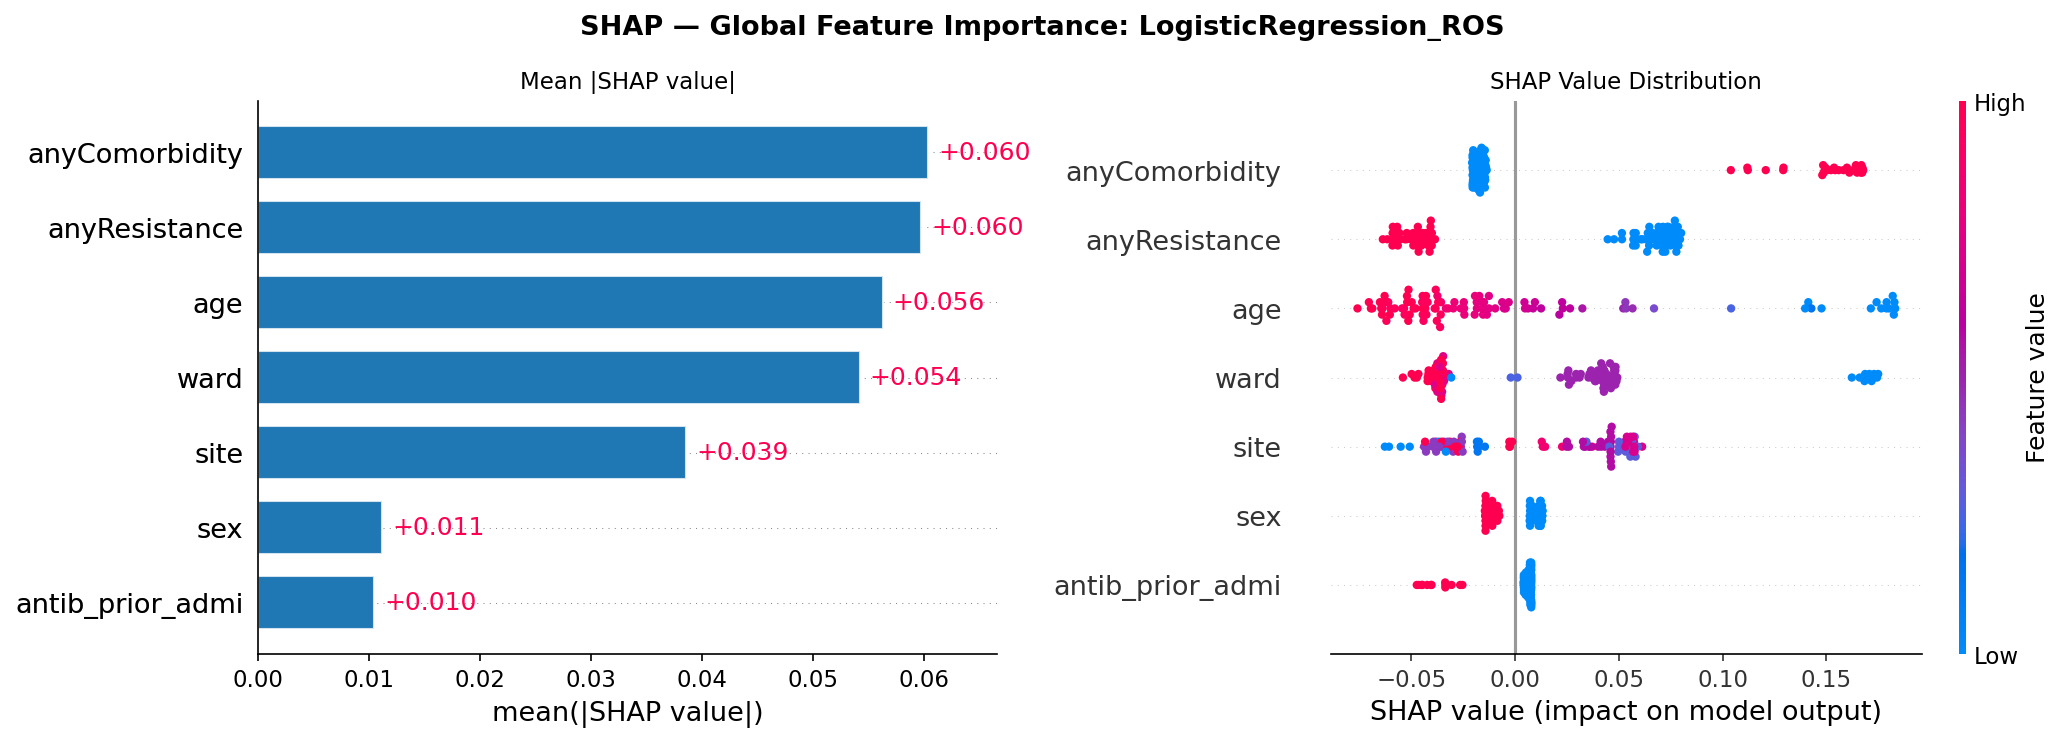

saved SHAP_beeswarm_LogisticRegression_ROS.png
Computing SHAP: SVM_ROS ... 

PermutationExplainer explainer: 101it [01:31,  1.02s/it]                         


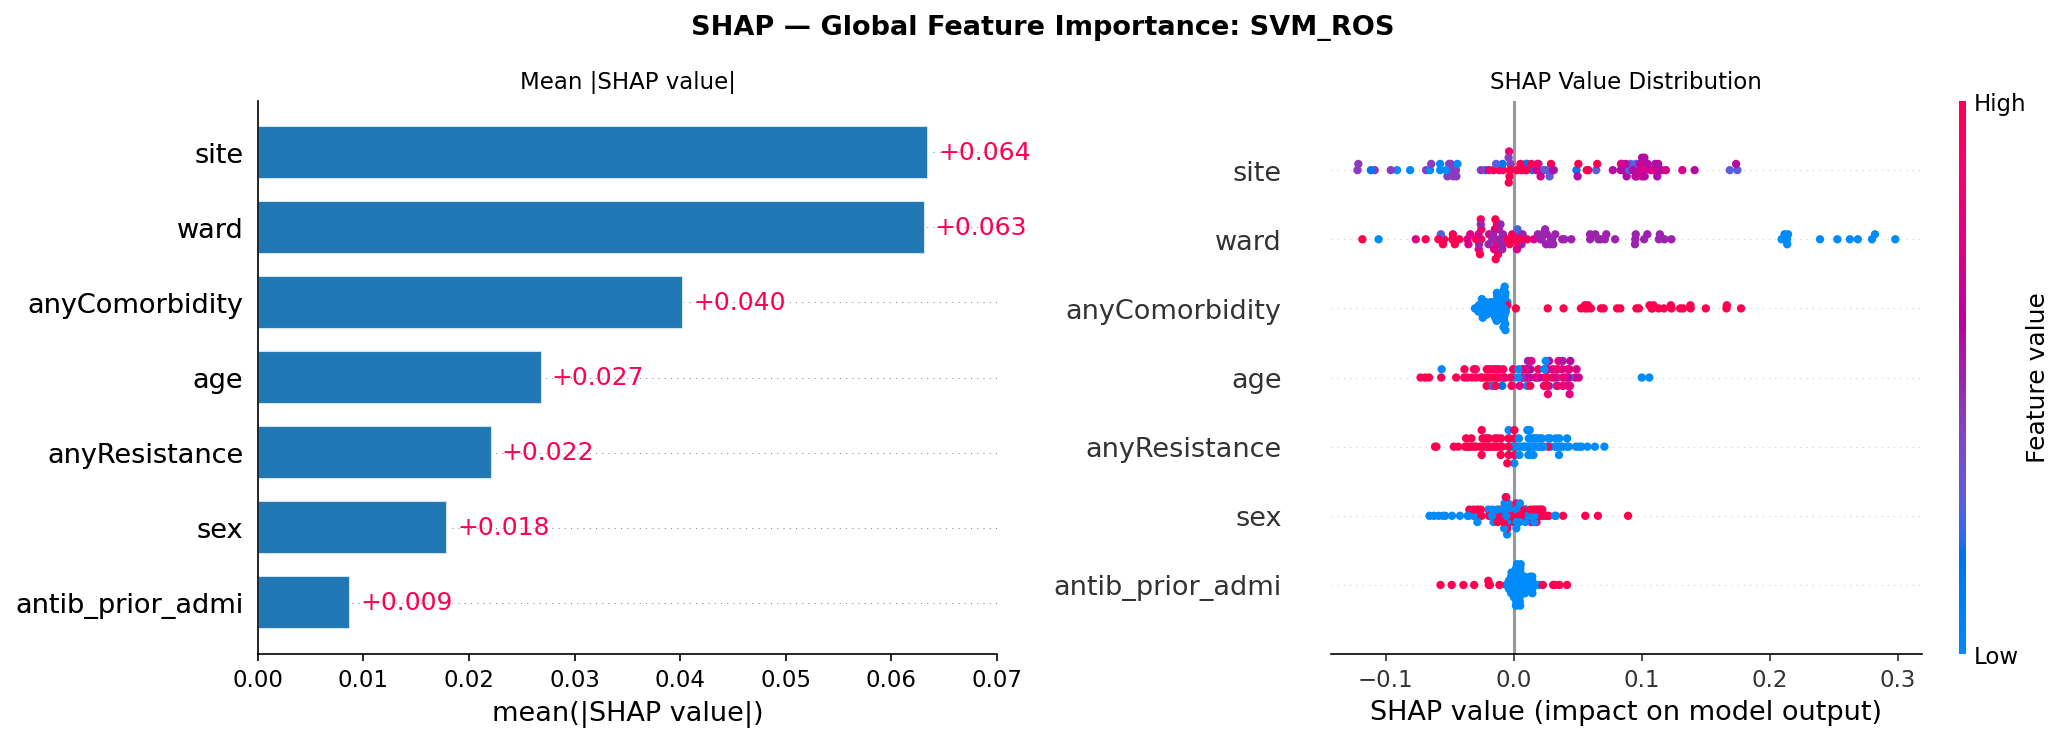

saved SHAP_beeswarm_SVM_ROS.png
Computing SHAP: RandomForest_ROS ... 

PermutationExplainer explainer: 101it [08:22,  5.08s/it]                         


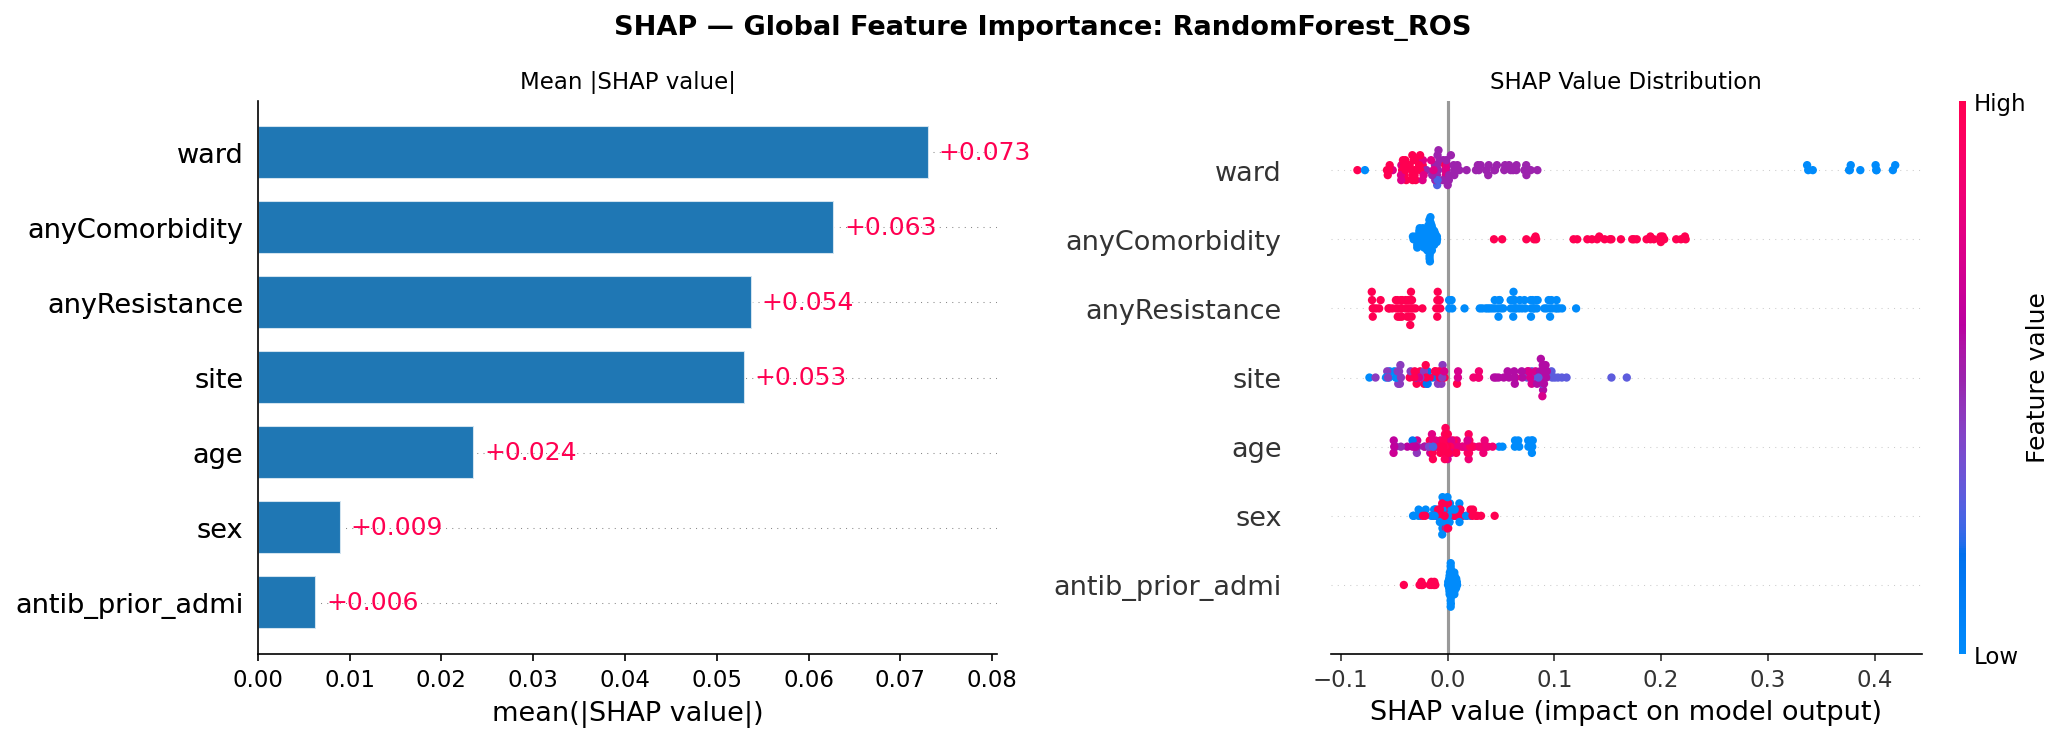

saved SHAP_beeswarm_RandomForest_ROS.png
Computing SHAP: ExtraTrees_ROS ... 

PermutationExplainer explainer: 101it [06:04,  3.76s/it]                         


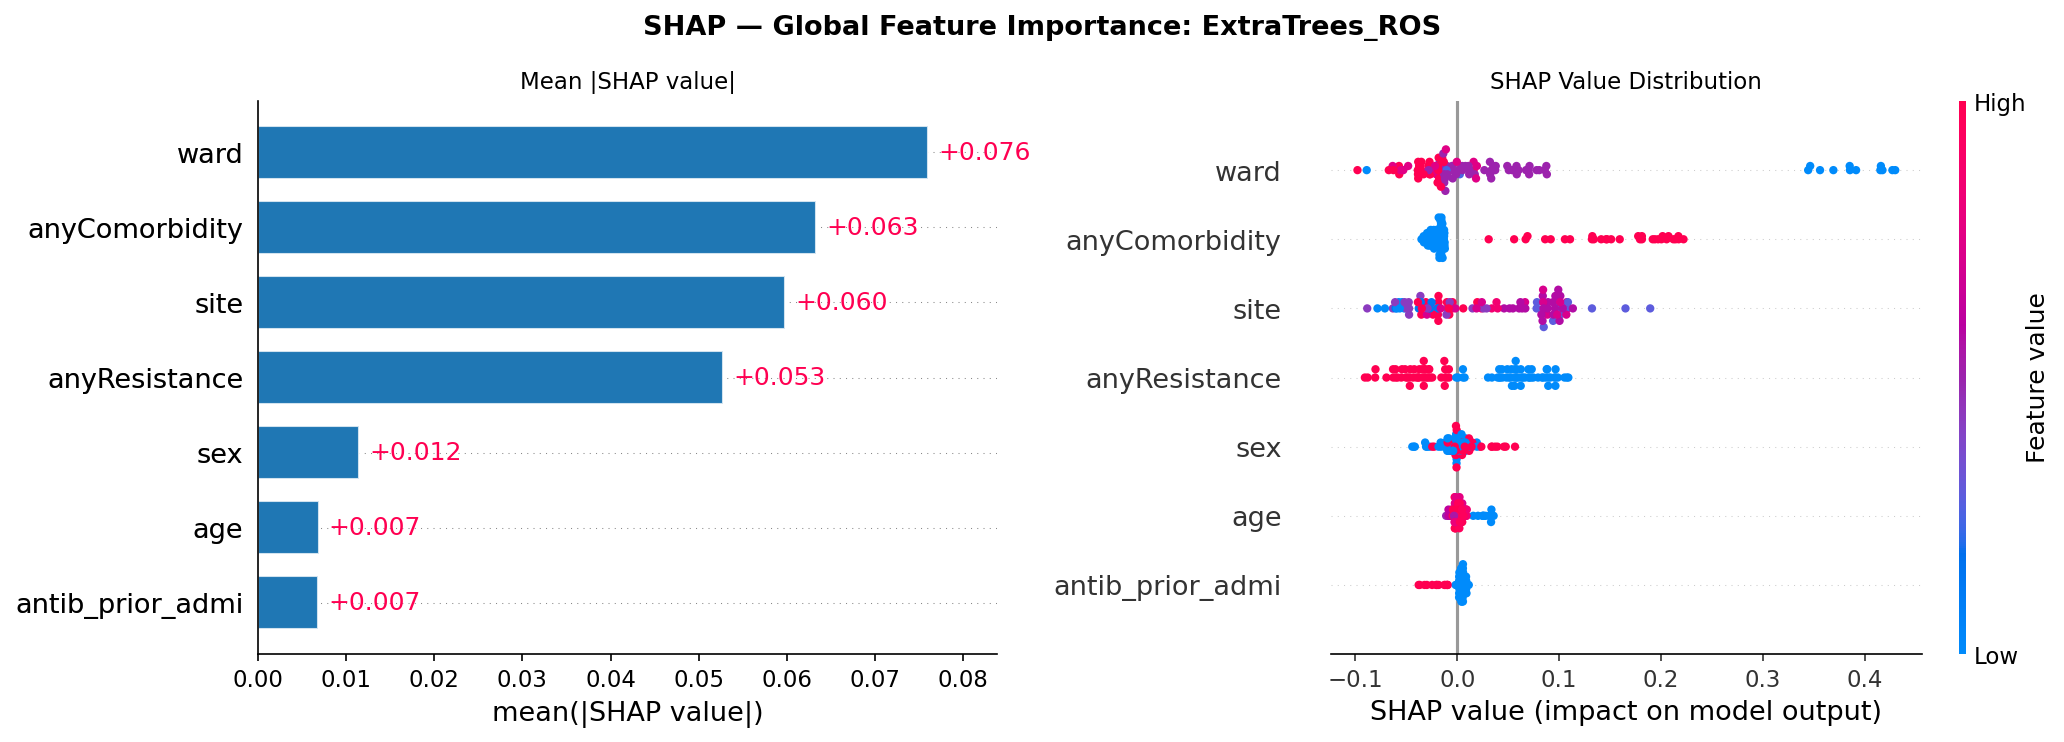

saved SHAP_beeswarm_ExtraTrees_ROS.png
Computing SHAP: BalancedRandomForest ... 

PermutationExplainer explainer: 101it [04:05,  2.56s/it]                         


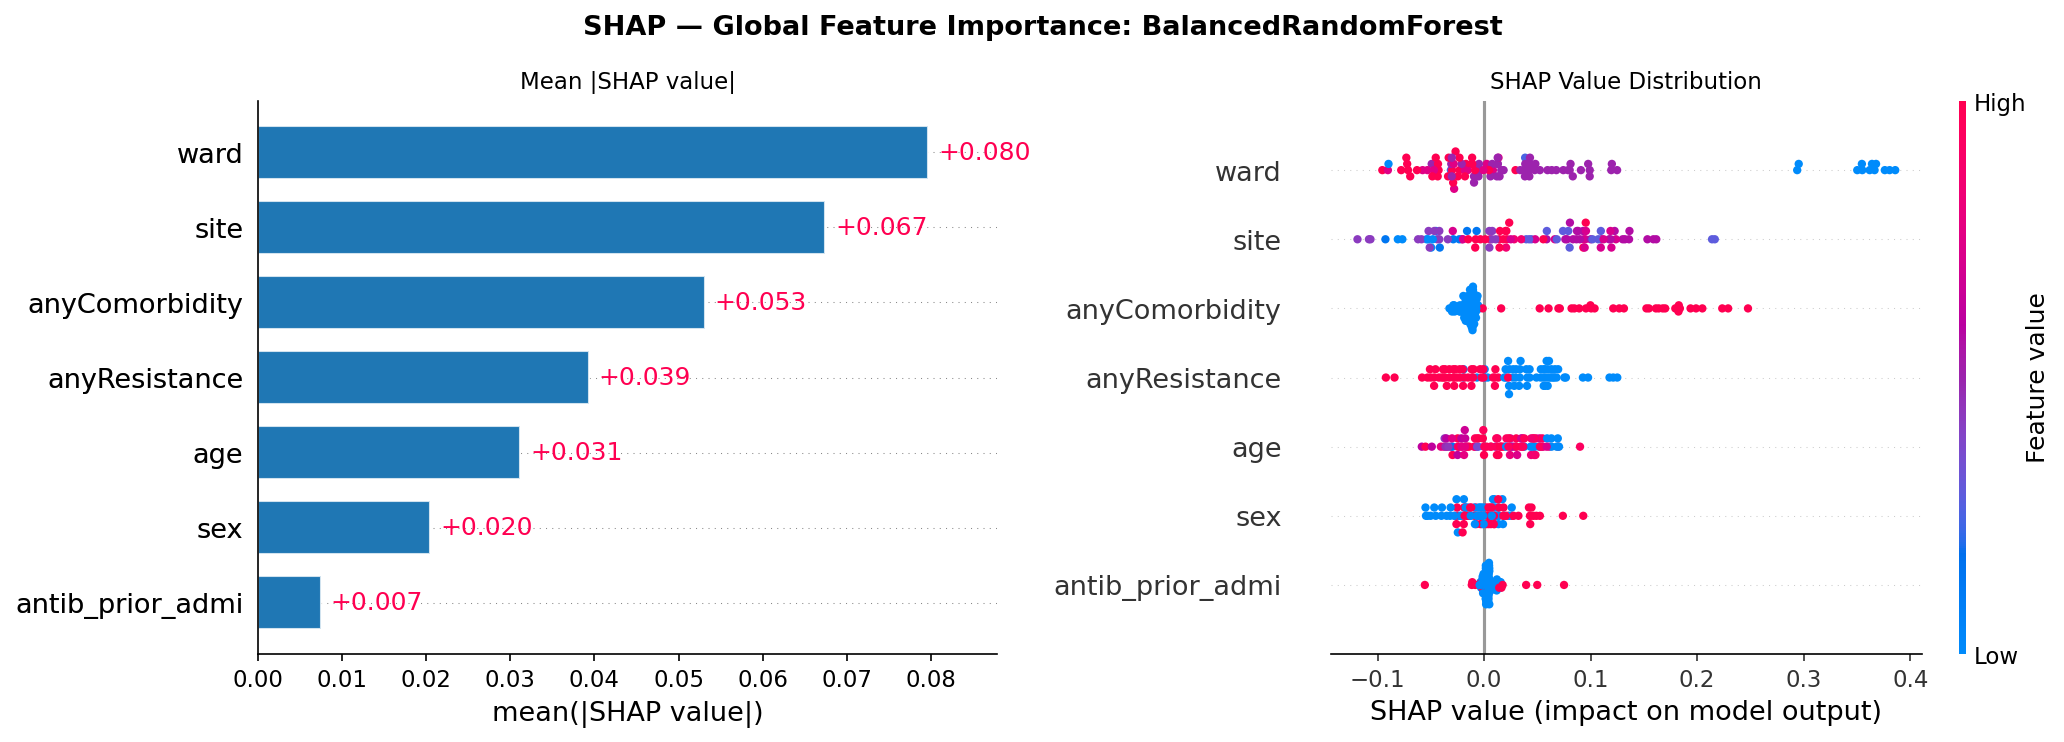

saved SHAP_beeswarm_BalancedRandomForest.png
Computing SHAP: EasyEnsemble ... 

PermutationExplainer explainer: 101it [1:07:14, 40.34s/it]                         


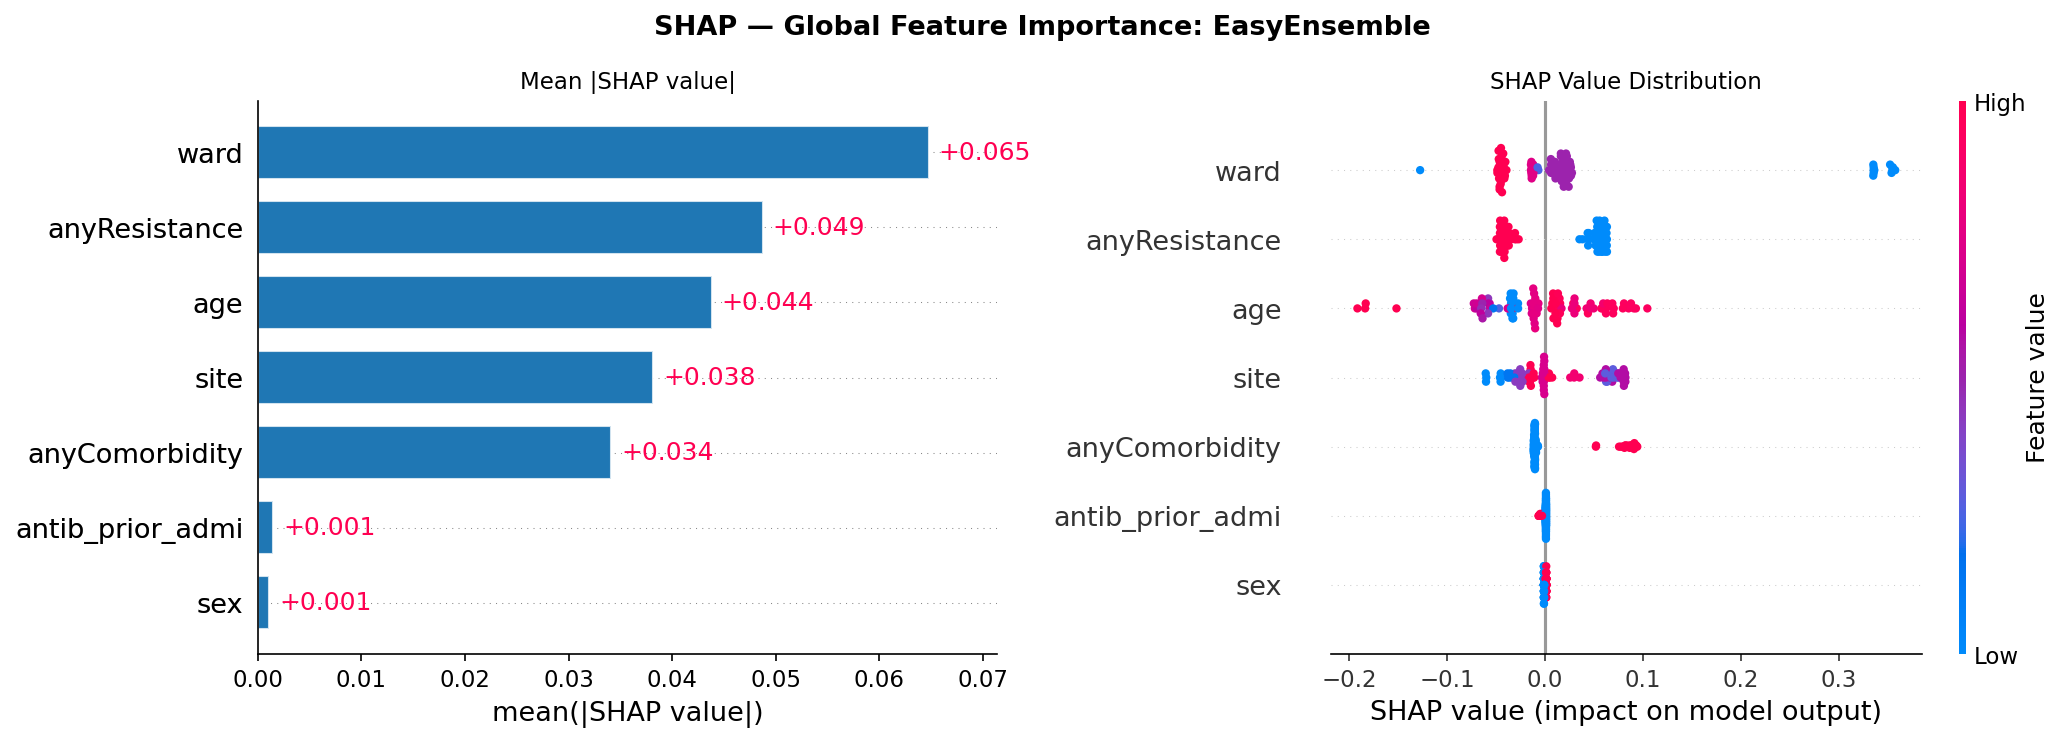

saved SHAP_beeswarm_EasyEnsemble.png
Computing SHAP: XGBoost_ROS ... 

PermutationExplainer explainer:  43%|████▎     | 43/100 [05:39<07:40,  8.08s/it]


KeyboardInterrupt: 

In [14]:

import shap

# ---- SHAP config ----
N_BG      = 30   # background samples for PermutationExplainer
N_EXPLAIN = 100  # test patients to explain

X_bg      = X_test.sample(N_BG, random_state=42)
X_explain = X_test.iloc[:N_EXPLAIN]

shap_store = {}   # model_name -> shap.Explanation

for mname, cal_model in cal_models.items():
    print(f"Computing SHAP: {mname} ...", end=" ", flush=True)

    predict_fn = make_predict_fn(cal_model, list(X_test.columns))
    explainer  = shap.PermutationExplainer(predict_fn, X_bg)
    sv         = explainer(X_explain)          # shap.Explanation object
    shap_store[mname] = sv

    # ---- side-by-side: bar (left) + beeswarm (right) ----
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"SHAP — Global Feature Importance: {mname}", fontsize=13, fontweight="bold")

    plt.sca(axes[0])
    shap.plots.bar(sv, max_display=7, show=False, ax=axes[0])

    # Recolor all bars to blue
    for patch in axes[0].patches:
        patch.set_facecolor('#1f77b4')

    # Fix annotations to 3 decimal places using the actual bar widths.
    # SHAP defaults to 2 d.p., which makes two features with the same rounded
    # label appear to have bars of equal length even when they differ.
    patches_sorted = sorted(axes[0].patches, key=lambda p: p.get_y())
    annot_texts = sorted(
        [t for t in axes[0].texts
         if t.get_text().lstrip('+-').replace('.', '', 1).isdigit()],
        key=lambda t: t.get_position()[1]
    )
    for patch, txt in zip(patches_sorted, annot_texts):
        txt.set_text(f'+{patch.get_width():.3f}')

    axes[0].set_title("Mean |SHAP value|")

    plt.sca(axes[1])
    # plot_size=None is required when supplying an ax to beeswarm
    shap.plots.beeswarm(sv, max_display=7, show=False, ax=axes[1], plot_size=None)
    axes[1].set_title("SHAP Value Distribution")

    plt.tight_layout()
    fname = f"SHAP_beeswarm_{mname}.png"
    fig.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {fname}")


## SHAP — Cross-model Feature Importance Comparison

Mean absolute SHAP values computed per feature per model and displayed as a grouped bar chart. Features that are tall across all models are robustly important regardless of algorithm.

                          site     age     sex  anyComorbidity  anyResistance  \
model                                                                           
LogisticRegression_ROS  0.0426  0.0698  0.0127          0.0740         0.0626   
SVM_ROS                 0.0516  0.0338  0.0234          0.0321         0.0211   
RandomForest_ROS        0.0482  0.0280  0.0132          0.0592         0.0517   
ExtraTrees_ROS          0.0502  0.0073  0.0166          0.0582         0.0493   
BalancedRandomForest    0.0465  0.0355  0.0247          0.0470         0.0362   
EasyEnsemble            0.0435  0.0508  0.0012          0.0416         0.0484   
XGBoost_ROS             0.0604  0.0660  0.0096          0.0298         0.0448   

                          ward  antib_prior_admi  
model                                             
LogisticRegression_ROS  0.0592            0.0105  
SVM_ROS                 0.0674            0.0076  
RandomForest_ROS        0.0831            0.0055  
ExtraTrees_ROS 

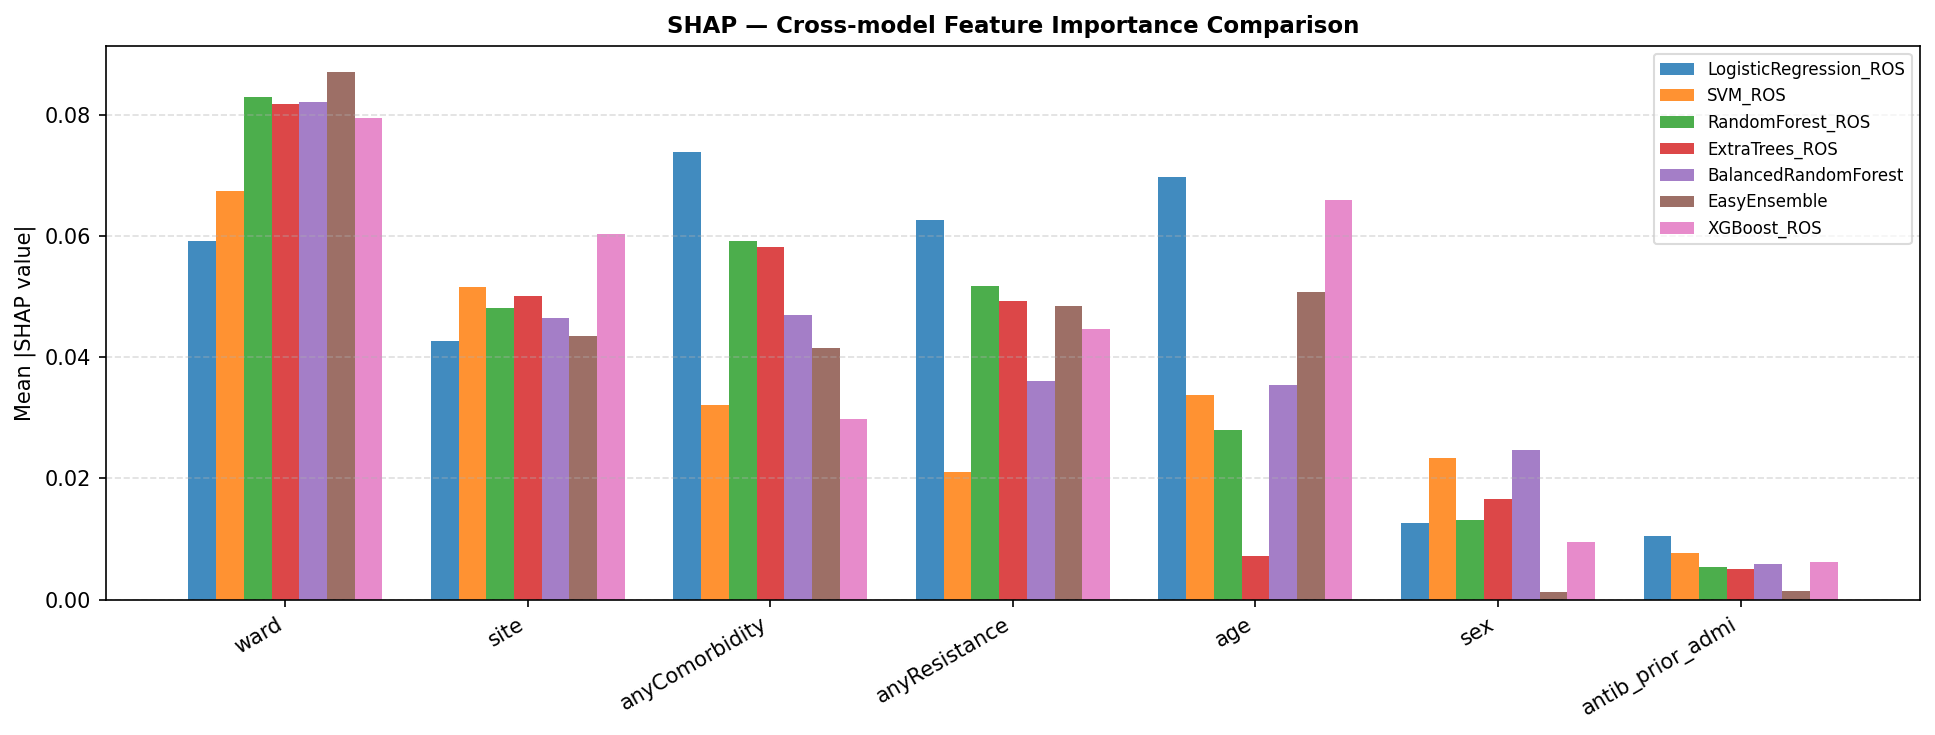

Saved SHAP_mean_abs_all_models.png


In [ ]:

# ---- Build mean |SHAP| table ----
feat_names = list(X_test.columns)

rows = []
for mname, sv in shap_store.items():
    mean_abs = np.abs(sv.values).mean(axis=0)
    row = {"model": mname}
    row.update(dict(zip(feat_names, mean_abs)))
    rows.append(row)

shap_importance_df = pd.DataFrame(rows).set_index("model")
shap_importance_df.to_csv("SHAP_mean_abs_importance_all_models.csv")
print(shap_importance_df.round(4))

# ---- Plot ----
feat_order = shap_importance_df.mean(axis=0).sort_values(ascending=False).index.tolist()
shap_importance_df = shap_importance_df[feat_order]

n_models  = len(MODEL_NAMES)
n_feats   = len(feat_order)
bar_w     = 0.8 / n_models
x         = np.arange(n_feats)

palette = plt.cm.tab10.colors

fig, ax = plt.subplots(figsize=(13, 5))
for k, mname in enumerate(MODEL_NAMES):
    offset = (k - n_models / 2 + 0.5) * bar_w
    ax.bar(x + offset, shap_importance_df.loc[mname, feat_order],
           width=bar_w, label=mname, color=palette[k % len(palette)], alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(feat_order, rotation=30, ha="right")
ax.set_ylabel("Mean |SHAP value|")
ax.set_title("SHAP — Cross-model Feature Importance Comparison", fontweight="bold")
ax.legend(loc="upper right", fontsize=8, framealpha=0.7)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
fig.savefig("SHAP_mean_abs_all_models.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved SHAP_mean_abs_all_models.png")
